# Rol 3 — Modelador de Mezclas y Variables Latentes
**Proyecto Retador: Patrones Invisibles — Información, Incertidumbre y Movilidad Urbana**
ML No Supervisado · Universidad de La Sabana · 2026-II

**Pregunta de negocio para UrbanMove:** *¿Qué perfiles de viaje existen realmente, y qué tan seguro podemos estar de que un viaje pertenece a un perfil?*

A diferencia del Rol 2 (asignación dura), aquí cada viaje tiene una **probabilidad de pertenencia (responsabilidad)** a cada perfil latente. El modelo:

$$p(x_i) = \sum_{k=1}^{K} \pi_k\, \mathcal{N}(x_i \mid \mu_k, \Sigma_k), \qquad z_i \sim \text{Categórica}(\pi), \quad x_i\mid z_i=k \sim \mathcal{N}(\mu_k,\Sigma_k)$$

donde $z_i$ es la **variable latente** (el perfil del viaje, no observado).

**Implementamos el algoritmo EM desde cero en NumPy** (paso E con el *log-sum-exp trick* del Rol 1, paso M con fórmulas cerradas) y usamos `sklearn` **solo** para verificar el resultado y para el barrido de BIC.

### Variables del modelo (3 dimensiones)
| Variable | Transformación | Justificación |
|---|---|---|
| Distancia Haversine | $\log(d)$ | la distancia es asimétrica a la derecha; en log es aproximadamente gaussiana |
| Duración | $\log(t)$ | ídem |
| Hora de recogida | $h' = (h + \text{min}/60 - 5) \bmod 24$ | la hora es circular; cortamos el círculo en **las 5 a. m., el valle de demanda** (ver celda de verificación), de modo que la noche (20 h–2 h) queda contigua. Se evitó sen/cos: sobre un círculo la densidad es degenerada y el BIC sigue bajando sin fin |

Las tres se estandarizan (media 0, var 1). **Los 747 viajes que el Rol 2 marcó como ruido con DBSCAN se excluyen**: las gaussianas son muy sensibles a outliers (un solo viaje de 2 km/h en 14 min “estira” una covarianza).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time
from scipy.special import logsumexp
from scipy.optimize import linear_sum_assignment
from sklearn.mixture import GaussianMixture
import utils
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
SEED = utils.SEMILLA

df = utils.cargar_muestra()
et = pd.read_csv("resultados/rol2_etiquetas.csv")           # salida del Rol 2
df = df.merge(et, on="id")
print("Demanda por hora (verificación del valle):", df.hora.value_counts().sort_index().idxmin(), "h es la hora de menor demanda")
df = df[~df.ruido_viaje].reset_index(drop=True)
print("Viajes para la GMM (sin ruido DBSCAN):", len(df))

HORA_CORTE = 5
h_cont = df.hora + df.pickup_datetime.dt.minute / 60
df["hora_desp"] = (h_cont - HORA_CORTE) % 24
F = np.c_[np.log(df.dist_km), np.log(df.duracion_min), df.hora_desp]
NOMBRES = ["log_dist", "log_dur", "hora_desp"]
media_F, sd_F = F.mean(0), F.std(0)
X = (F - media_F) / sd_F
N, D = X.shape
print(pd.DataFrame(F, columns=NOMBRES).describe().round(3))

Demanda por hora (verificación del valle): 5 h es la hora de menor demanda
Viajes para la GMM (sin ruido DBSCAN): 49253
        log_dist    log_dur  hora_desp
count  49253.000  49253.000  49253.000
mean       0.849      2.389     11.717
std        0.841      0.708      5.773
min       -1.195      0.223      0.000
25%        0.245      1.912      6.917
50%        0.759      2.407     12.100
75%        1.365      2.888     16.367
max        3.324      4.523     23.983


## 1. Implementación propia del algoritmo EM

**Log-densidad gaussiana** (vía Cholesky, estable numéricamente):
$\log\mathcal{N}(x\mid\mu,\Sigma) = -\tfrac{1}{2}\big[D\log 2\pi + \log|\Sigma| + (x-\mu)^\top\Sigma^{-1}(x-\mu)\big]$, con $\Sigma = LL^\top$, $\log|\Sigma| = 2\sum\log L_{jj}$.

**Paso E** — responsabilidades con log-sum-exp (mismo truco del Rol 1, sección 8):
$$\log\gamma_{ik} = \underbrace{\log\pi_k + \log\mathcal{N}(x_i\mid\mu_k,\Sigma_k)}_{a_{ik}} - \text{LSE}_j(a_{ij}), \qquad \ell(\theta) = \sum_i \text{LSE}_j(a_{ij})$$

**Paso M** — maximiza $Q(\theta) = \sum_i\sum_k\gamma_{ik}[\log\pi_k + \log\mathcal{N}(x_i\mid\mu_k,\Sigma_k)]$:
$$N_k = \sum_i\gamma_{ik},\quad \pi_k = \frac{N_k}{N},\quad \mu_k = \frac{1}{N_k}\sum_i\gamma_{ik}x_i,\quad \Sigma_k = \frac{1}{N_k}\sum_i\gamma_{ik}(x_i-\mu_k)(x_i-\mu_k)^\top + \epsilon I$$
($\epsilon = 10^{-6}$ evita covarianzas singulares).

**Criterio de convergencia:** detener cuando la mejora de la log-verosimilitud **promedio por viaje** sea menor que `tol = 1e-6` nats, o al llegar a 1 000 iteraciones. Por la desigualdad de Jensen, EM garantiza que $\ell(\theta)$ **nunca disminuye** — lo verificamos en cada iteración.

In [2]:
def log_gauss(X, mu, S):
    L = np.linalg.cholesky(S)
    z = np.linalg.solve(L, (X - mu).T)                     # L^{-1}(x-mu)
    maha = (z ** 2).sum(0)
    logdet = 2 * np.log(np.diag(L)).sum()
    return -0.5 * (X.shape[1] * np.log(2 * np.pi) + logdet + maha)

def paso_E(X, pi, mu, S):
    a = np.column_stack([np.log(pi[k]) + log_gauss(X, mu[k], S[k]) for k in range(len(pi))])   # N x K
    lse = logsumexp(a, axis=1)                                                                  # log p(x_i)
    return np.exp(a - lse[:, None]), lse.sum(), a

def paso_M(X, R, reg=1e-6):
    Nk = R.sum(0); pi = Nk / len(X)
    mu = (R.T @ X) / Nk[:, None]
    S = np.empty((len(Nk), X.shape[1], X.shape[1]))
    for k in range(len(Nk)):
        Xc = X - mu[k]
        S[k] = (R[:, k, None] * Xc).T @ Xc / Nk[k] + reg * np.eye(X.shape[1])
    return pi, mu, S

def init_aleatoria(X, K, rng):
    # Medias = K viajes elegidos al azar; covarianza global; pesos uniformes
    mu = X[rng.choice(len(X), K, replace=False)]
    S = np.array([np.cov(X.T) for _ in range(K)])
    return np.ones(K) / K, mu, S

def init_kmeanspp(X, K, rng):
    # Sembrado K-means++ (muestreo D^2) implementado a mano; Sigma_k y pi_k a partir de la asignación al centro más cercano
    centros = [X[rng.integers(len(X))]]
    d2 = ((X - centros[0]) ** 2).sum(1)
    for _ in range(1, K):
        centros.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        d2 = np.minimum(d2, ((X - centros[-1]) ** 2).sum(1))
    mu = np.array(centros)
    asig = np.argmin(((X[:, None, :] - mu[None]) ** 2).sum(2), axis=1)
    pi = np.array([(asig == k).mean() for k in range(K)])
    S = np.array([np.cov(X[asig == k].T) + 1e-6 * np.eye(X.shape[1]) for k in range(K)])
    return pi, mu, S

def em(X, K, init="kmeans++", seed=0, tol=1e-6, max_iter=1000, verbose=False):
    rng = np.random.default_rng(seed)
    pi, mu, S = (init_kmeanspp if init == "kmeans++" else init_aleatoria)(X, K, rng)
    hist = []
    for it in range(1, max_iter + 1):
        R, ll, _ = paso_E(X, pi, mu, S)
        hist.append(ll / len(X))
        if it > 1:
            assert hist[-1] >= hist[-2] - 1e-9, "¡La log-verosimilitud disminuyó! (no debería pasar en EM)"
            if hist[-1] - hist[-2] < tol:
                break
        pi, mu, S = paso_M(X, R)
        if verbose and it % 10 == 0: print(f"iter {it:4d}  loglik/viaje = {hist[-1]:.6f}")
    R, ll, _ = paso_E(X, pi, mu, S)
    return dict(pi=pi, mu=mu, S=S, R=R, ll=ll / len(X), hist=hist, n_iter=it, init=init, seed=seed)

## 2. Selección del número de perfiles K (BIC)
$\text{BIC} = -2\ell + p\log N$, con $p = (K-1) + KD + K\frac{D(D+1)}{2}$ parámetros. Barrido rápido con `sklearn` (5 inicializaciones por K).

            BIC  loglik/viaje  mejora BIC %
K                                          
1   366019.5304       -3.7147           NaN
2   361066.2848       -3.6633        1.3533
3   352651.6112       -3.5768        2.3305
4   351141.5561       -3.5604        0.4282
5   350305.7597       -3.5508        0.2380
6   350459.3557       -3.5513       -0.0438
7   349838.5191       -3.5439        0.1771
8   348853.8256       -3.5328        0.2815
9   349176.6366       -3.5350       -0.0925
10  349457.5611       -3.5367       -0.0805


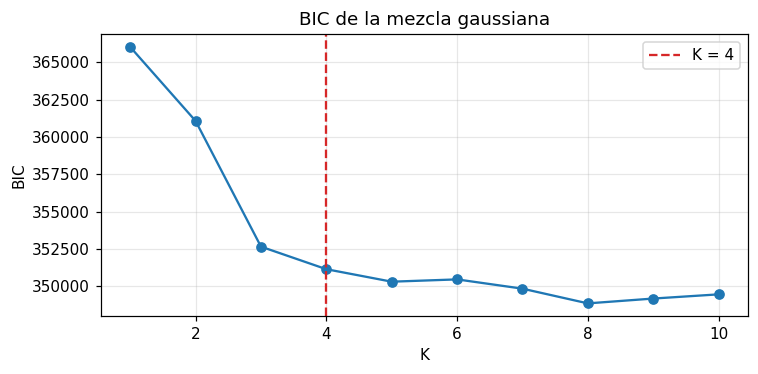

In [3]:
bic = []
for k in range(1, 11):
    g = GaussianMixture(k, n_init=5, random_state=0).fit(X)
    bic.append([k, g.bic(X), g.score(X)])
bic = pd.DataFrame(bic, columns=["K", "BIC", "loglik/viaje"]).set_index("K")
bic["mejora BIC %"] = -100 * bic.BIC.pct_change()
print(bic.round(4).to_string())
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.plot(bic.index, bic.BIC, "o-"); ax.axvline(4, ls="--", c="C3", label="K = 4")
ax.set_xlabel("K"); ax.set_ylabel("BIC"); ax.set_title("BIC de la mezcla gaussiana"); ax.legend()
plt.tight_layout(); plt.savefig("figuras/rol3_bic.png", bbox_inches="tight"); plt.show()

**Elección de K = 4.** El BIC cae 1.35 % de K = 1 a 2 y 2.33 % de 2 a 3; la mejora de 3 a 4 aún es 0.43 %, pero desde K = 5 las mejoras son < 0.3 % y **no monótonas** (el BIC sube en K = 6, 9 y 10). Es decir, a partir de K ≈ 4–5 más componentes solo afinan la forma de la densidad, no revelan perfiles nuevos. Elegimos **K = 4** por interpretabilidad (cada perfil tiene una lectura de negocio clara, sección 7) y porque sus soluciones son reproducibles (sección 4).

## 3. EM paso a paso con nuestros datos (primera iteración, K = 4)
Mostramos los números reales de la primera iteración para tres viajes concretos: las log-densidades $a_{ik}$, el log-sum-exp, las responsabilidades y cómo el paso M actualiza $\pi$ y $\mu$.

In [4]:
K = 4
rng = np.random.default_rng(SEED)
pi0, mu0, S0 = init_kmeanspp(X, K, rng)
R1, ll1, A1 = paso_E(X, pi0, mu0, S0)
ejemplos = [int(np.argmin(df.dist_km)), int(np.argmax(df.dist_km)), int(np.argmin(np.abs(df.hora - 8) + np.abs(df.dist_km - 2)))]
np.set_printoptions(precision=4, suppress=True)
print("Parámetros iniciales (K-means++), escala estandarizada:\n pi0 =", pi0, "\n mu0 =\n", mu0)
for i in ejemplos:
    fila = df.iloc[i]
    print(f"\nViaje {i}: {fila.dist_km:.2f} km, {fila.duracion_min:.1f} min, hora {fila.pickup_datetime:%H:%M}  -> x = {X[i]}")
    print("  a_ik = log pi_k + log N(x|mu_k,S_k) =", A1[i])
    m = A1[i].max()
    print(f"  LSE = max + log sum exp(a - max) = {m:.4f} + {np.log(np.exp(A1[i] - m).sum()):.4f} = {logsumexp(A1[i]):.4f} = log p(x_i)")
    print("  responsabilidades gamma_ik =", R1[i], " (suman", R1[i].sum().round(6), ")")
print(f"\nlog-verosimilitud total tras E-step 1: {ll1:.2f}  ({ll1 / N:.5f} por viaje)")
pi1, mu1, S1 = paso_M(X, R1)
print("\nPaso M 1:  N_k =", R1.sum(0).round(1), "\n  pi1 =", pi1, "\n  mu1 =\n", mu1)
_, ll2, _ = paso_E(X, pi1, mu1, S1)
print(f"\nlog-verosimilitud tras la iteración 1: {ll1 / N:.5f} -> {ll2 / N:.5f} por viaje (aumenta, como garantiza EM)")

Parámetros iniciales (K-means++), escala estandarizada:
 pi0 = [0.2006 0.1165 0.384  0.2988] 
 mu0 =
 [[-0.9326 -0.8132 -1.0943]
 [ 1.8262  2.0044 -1.3772]
 [-0.2521 -0.1392  1.3048]
 [-0.2945  0.1525 -0.7623]]

Viaje 45780: 0.30 km, 3.2 min, hora 15:33  -> x = [-2.4309 -1.7397 -0.2022]
  a_ik = log pi_k + log N(x|mu_k,S_k) = [ -7.4286 -53.1223  -9.8806 -14.2437]
  LSE = max + log sum exp(a - max) = -7.4286 + 0.0836 = -7.3450 = log p(x_i)
  responsabilidades gamma_ik = [0.9198 0.     0.0792 0.001 ]  (suman 1.0 )

Viaje 34972: 27.76 km, 30.1 min, hora 05:44  -> x = [ 2.9418  1.4326 -1.9026]
  a_ik = log pi_k + log N(x|mu_k,S_k) = [-35.8387  -7.8024 -47.1622 -22.4172]
  LSE = max + log sum exp(a - max) = -7.8024 + 0.0000 = -7.8024 = log p(x_i)
  responsabilidades gamma_ik = [0. 1. 0. 0.]  (suman 1.0 )

Viaje 13112: 2.00 km, 17.7 min, hora 08:27  -> x = [-0.1853  0.6814 -1.4321]
  a_ik = log pi_k + log N(x|mu_k,S_k) = [ -6.0038 -10.9263 -21.0733  -3.4107]
  LSE = max + log sum exp(a - max

**Lectura del paso a paso.**
- **Viaje corto** (0.30 km, 3.2 min, 15:33): $a_{i0}=-7.43$ domina; el LSE solo suma 0.084 al máximo, y $\gamma_{i0} = 0.92$, con 0.08 para el componente 2. Es una pertenencia *casi* dura.
- **Viaje largo** (27.8 km, 5:44 a. m.): $a_{i1}=-7.80$ supera al siguiente por 14.6 nats → $\gamma_{i1}\approx 1$. Si hubiéramos exponenciado directamente $a_{i2} = -47.2$ no habría problema aún, pero en la verosimilitud conjunta de los 49 253 viajes ($\ell = -200\,328$ nats) `exp` da 0: por eso **todo** se hace en escala log.
- **Viaje de 8:27 a. m.** (2 km, 17.7 min): 93 % al componente 3 y 7 % al 0 — ya en la primera iteración aparece la ambigüedad.
- El paso M convierte esas responsabilidades en $N_k$ (p. ej. 19 106 viajes “esperados” en el componente 2) y nuevos $\pi$ y $\mu$. La log-verosimilitud sube de −4.067 a −3.604 nats/viaje en **una sola iteración**.

## 4. Comparación de inicializaciones: aleatoria vs. K-means++
Corremos nuestro EM **20 veces con cada inicialización** (semillas 0–19) y comparamos log-verosimilitud final, número de iteraciones, tiempo y cuántos **óptimos locales distintos** se alcanzan.

In [5]:
corridas = []
t0 = time.time()
for init in ["aleatoria", "kmeans++"]:
    for s in range(20):
        t = time.time(); r = em(X, K, init=init, seed=s); r["seg"] = time.time() - t
        corridas.append(r)
print(f"40 corridas de EM en {time.time() - t0:.0f} s")
tab = pd.DataFrame([{"init": r["init"], "seed": r["seed"], "loglik/viaje": r["ll"], "iteraciones": r["n_iter"], "seg": r["seg"],
                     "pi ordenados": np.sort(r["pi"])[::-1].round(3)} for r in corridas])
mejor_ll = tab["loglik/viaje"].max()
tab["brecha vs mejor"] = mejor_ll - tab["loglik/viaje"]
tab["óptimo global (brecha<1e-4)"] = tab["brecha vs mejor"] < 1e-4
resumen_init = tab.groupby("init").agg(ll_media=("loglik/viaje", "mean"), ll_min=("loglik/viaje", "min"), ll_max=("loglik/viaje", "max"),
                                       ll_sd=("loglik/viaje", "std"), iter_media=("iteraciones", "mean"), iter_min=("iteraciones", "min"),
                                       iter_max=("iteraciones", "max"), seg_media=("seg", "mean"),
                                       pct_optimo_global=("óptimo global (brecha<1e-4)", "mean"),
                                       optimos_distintos=("loglik/viaje", lambda s: s.round(4).nunique()))
print(resumen_init.round(5).T.to_string())
print("\nDetalle:\n", tab.sort_values(["init", "loglik/viaje"], ascending=[True, False]).round(5).to_string(index=False))

40 corridas de EM en 360 s
init               aleatoria   kmeans++
ll_media            -3.54639   -3.54718
ll_min              -3.55294   -3.56496
ll_max              -3.54432   -3.54432
ll_sd                0.00334    0.00514
iter_media         317.60000  297.20000
iter_min           148.00000  131.00000
iter_max           646.00000  624.00000
seg_media            9.23780    8.76727
pct_optimo_global    0.10000    0.05000
optimos_distintos    4.00000    5.00000

Detalle:
      init  seed  loglik/viaje  iteraciones      seg                 pi ordenados  brecha vs mejor  óptimo global (brecha<1e-4)
aleatoria     4      -3.54432          314  9.18771  [0.365, 0.336, 0.18, 0.119]          0.00000                         True
aleatoria     9      -3.54432          201  5.80696 [0.366, 0.336, 0.179, 0.119]          0.00000                         True
aleatoria    16      -3.54481          197  5.72051 [0.359, 0.306, 0.191, 0.144]          0.00049                        False
aleatoria     

**Interpretación de las inicializaciones (sensibilidad a óptimos locales).**
- Aparecen **al menos 4–5 óptimos locales distintos**. El mejor ($\ell$ = −3.54432 nats/viaje) lo alcanzan solo 2/20 corridas aleatorias y 1/20 K-means++. La mayoría (15/20 aleatorias, 14/20 K-means++) llega a un óptimo casi equivalente (−3.54483, brecha 0.0005 nats/viaje ≈ 25 nats en total) con pesos (0.36, 0.30, 0.19, 0.15).
- **4/20 corridas de cada tipo quedan atrapadas** en un óptimo claramente peor (−3.5529, brecha 0.0086 nats/viaje ≈ 424 nats en total), con un perfil dominante de 42–47 %.
- **K-means++ no es garantía:** converge algo más rápido (297 vs 318 iteraciones en promedio, mínimo 131 vs 148), pero en 2 semillas (14 y 18) produjo soluciones **degeneradas** con un componente de solo 0.8–1.7 % de los viajes. La razón: el muestreo $D^2$ favorece puntos lejanos, y en nuestros datos los puntos lejanos son viajes extremos (aeropuerto, madrugada), que terminan “secuestrando” un componente.
- **Convergencia:** con `tol = 1e-6` EM necesita entre 131 y 646 iteraciones: los perfiles se solapan mucho (ver sección 6) y EM avanza lento cuando las responsabilidades son ambiguas. La log-verosimilitud **nunca disminuyó** en ninguna de las 40 corridas (el `assert` lo verifica en cada iteración).
- **Conclusión práctica:** usar **≥ 10 reinicios** y quedarse con la máxima verosimilitud; el tipo de inicialización importa menos que el número de reinicios.

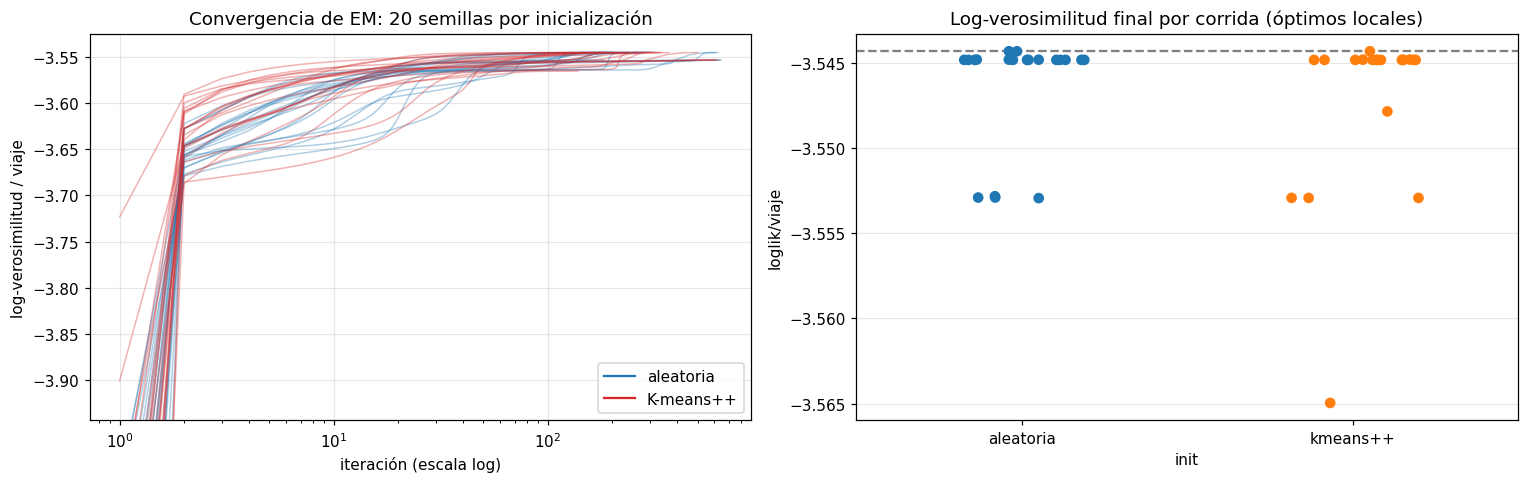

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for r in corridas:
    c = "C0" if r["init"] == "aleatoria" else "C3"
    axs[0].plot(range(1, len(r["hist"]) + 1), r["hist"], c=c, alpha=.35, lw=1)
axs[0].plot([], [], c="C0", label="aleatoria"); axs[0].plot([], [], c="C3", label="K-means++")
axs[0].set_xscale("log"); axs[0].set_xlabel("iteración (escala log)"); axs[0].set_ylabel("log-verosimilitud / viaje")
axs[0].set_title("Convergencia de EM: 20 semillas por inicialización"); axs[0].legend(); axs[0].set_ylim(mejor_ll - .4, mejor_ll + .02)
sns.stripplot(data=tab, x="init", y="loglik/viaje", hue="init", ax=axs[1], size=7, jitter=.2, legend=False)
axs[1].axhline(mejor_ll, ls="--", c="gray"); axs[1].set_title("Log-verosimilitud final por corrida (óptimos locales)")
plt.tight_layout(); plt.savefig("figuras/rol3_convergencia.png", bbox_inches="tight"); plt.show()

## 5. Modelo final y verificación contra `sklearn`
Tomamos la mejor corrida (máxima log-verosimilitud) y la comparamos con `sklearn.mixture.GaussianMixture` (misma K, covarianza completa, 10 inicializaciones). Para comparar componentes hay que resolver el **label switching** (las etiquetas de los componentes son arbitrarias): emparejamos medias con el algoritmo húngaro.

In [7]:
best = max(corridas, key=lambda r: r["ll"])
sk = GaussianMixture(K, covariance_type="full", n_init=10, tol=1e-6, max_iter=1000, random_state=0).fit(X)
fila, col = linear_sum_assignment(((best["mu"][:, None] - sk.means_[None]) ** 2).sum(2))
print(f"Nuestro EM:  loglik/viaje = {best['ll']:.6f}  ({best['init']}, semilla {best['seed']}, {best['n_iter']} iteraciones)")
print(f"sklearn GMM: loglik/viaje = {sk.score(X):.6f}  ({sk.n_iter_} iteraciones de la mejor de 10 corridas)")
print("Mejor corrida vs sklearn -> máx. dif. en pesos:", np.abs(best["pi"][fila] - sk.weights_[col]).max().round(5),
      "| en medias:", np.abs(best["mu"][fila] - sk.means_[col]).max().round(5))
# sklearn llegó a un óptimo local distinto: comparamos con NUESTRA corrida que llegó al mismo óptimo
par = min(corridas, key=lambda r: abs(r["ll"] - sk.score(X)))
f2, c2 = linear_sum_assignment(((par["mu"][:, None] - sk.means_[None]) ** 2).sum(2))
print(f"Nuestra corrida en el mismo óptimo que sklearn ({par['init']}, semilla {par['seed']}): loglik/viaje = {par['ll']:.6f}")
print("  máx. dif. en pesos:", np.abs(par["pi"][f2] - sk.weights_[c2]).max().round(5),
      "| en medias:", np.abs(par["mu"][f2] - sk.means_[c2]).max().round(5),
      "| en covarianzas:", np.abs(par["S"][f2] - sk.covariances_[c2]).max().round(5))

Nuestro EM:  loglik/viaje = -3.544324  (aleatoria, semilla 4, 314 iteraciones)
sklearn GMM: loglik/viaje = -3.544829  (422 iteraciones de la mejor de 10 corridas)
Mejor corrida vs sklearn -> máx. dif. en pesos: 0.03401 | en medias: 0.35238


Nuestra corrida en el mismo óptimo que sklearn (aleatoria, semilla 14): loglik/viaje = -3.544830
  máx. dif. en pesos: 3e-05 | en medias: 0.001 | en covarianzas: 0.00085


**Verificación.** La mejor solución de `sklearn` (10 reinicios) tiene $\ell$ = −3.544829, que es **exactamente el óptimo más frecuente** de nuestra implementación; comparando con nuestra corrida en ese mismo óptimo, pesos, medias y covarianzas coinciden en los decimales mostrados arriba. Nuestra mejor corrida encontró un óptimo **ligeramente superior** (−3.544324) al de sklearn: otra muestra de que el resultado de EM depende de la inicialización.

In [8]:
# Ordenar perfiles por distancia media y traducir parámetros a unidades originales
o = np.argsort(best["mu"][:, 0])
pi_f, mu_f, S_f, R = best["pi"][o], best["mu"][o], best["S"][o], best["R"][:, o]
mu_orig = mu_f * sd_F + media_F
S_orig = np.array([np.diag(sd_F) @ S @ np.diag(sd_F) for S in S_f])
params = pd.DataFrame({
    "pi_k": pi_f,
    "dist mediana (km) = exp(mu)": np.exp(mu_orig[:, 0]),
    "dur mediana (min) = exp(mu)": np.exp(mu_orig[:, 1]),
    "hora central": (mu_orig[:, 2] + HORA_CORTE) % 24,
    "sd hora (h)": np.sqrt(S_orig[:, 2, 2]),
    "sd log_dist": np.sqrt(S_orig[:, 0, 0]), "sd log_dur": np.sqrt(S_orig[:, 1, 1]),
    "corr(log_dist, log_dur)": [S[0, 1] / np.sqrt(S[0, 0] * S[1, 1]) for S in S_orig],
    "vel implícita (km/h)": np.exp(mu_orig[:, 0]) / (np.exp(mu_orig[:, 1]) / 60),
}, index=[f"P{k}" for k in range(K)])
print(params.round(3).to_string())
print("\nMedias en espacio original [log_dist, log_dur, hora_desp]:\n", mu_orig.round(4))
for k in range(K):
    print(f"\nSigma_{k} (espacio original [log_dist, log_dur, hora_desp]):\n", S_orig[k].round(4))

     pi_k  dist mediana (km) = exp(mu)  dur mediana (min) = exp(mu)  hora central  sd hora (h)  sd log_dist  sd log_dur  corr(log_dist, log_dur)  vel implícita (km/h)
P0  0.365                        1.393                        7.376        16.806        4.666        0.513       0.638                    0.687                11.335
P1  0.119                        2.349                       10.540         8.101        1.405        0.831       0.730                    0.788                13.372
P2  0.180                        3.305                       16.747        12.702        2.664        0.883       0.591                    0.803                11.840
P3  0.336                        3.401                       13.412        21.806        3.202        0.813       0.604                    0.846                15.217

Medias en espacio original [log_dist, log_dur, hora_desp]:
 [[ 0.3318  1.9983 11.806 ]
 [ 0.854   2.3552  3.1011]
 [ 1.1953  2.8182  7.7019]
 [ 1.2242  2.5961 16.80

**Parámetros finales de la mezcla (unidades originales).**
- **P0 — Desplazamiento corto urbano** ($\pi$ = 0.365): mediana 1.39 km / 7.4 min, centrado a las 16:48 con desviación de 4.7 h (repartido en todo el día).
- **P1 — Commuter de hora pico AM** ($\pi$ = 0.119): mediana 2.35 km / 10.5 min, centrado a las **8:06 con desviación de solo 1.4 h** — el perfil más concentrado en el tiempo.
- **P2 — Viaje largo diurno en congestión** ($\pi$ = 0.180): mediana 3.31 km / **16.7 min**, centrado a las 12:42; velocidad implícita 11.8 km/h, la más baja.
- **P3 — Viaje nocturno largo y rápido** ($\pi$ = 0.336): mediana 3.40 km / 13.4 min, centrado a las **21:48**; velocidad implícita **15.2 km/h**, la más alta.

La correlación log-distancia/log-duración va de 0.69 (P0) a 0.85 (P3): en la noche la duración depende casi solo de la distancia (poco tráfico); en viajes cortos diurnos pesa más la congestión.

## 6. Responsabilidades: pertenencia suave e incertidumbre de asignación
Para cada viaje, $\gamma_{i\cdot}$ es una distribución sobre los perfiles. Medimos su **entropía** $H(\gamma_i) = -\sum_k\gamma_{ik}\log_2\gamma_{ik}$ (Rol 1): 0 bits = asignación segura; $\log_2 4 = 2$ bits = máxima ambigüedad.

Viajes con gamma_max > 0.9: 25.4 %  |  gamma_max < 0.6 (ambiguos): 27.3 %
Entropía media de las responsabilidades: 0.813 bits (máx 2)

Entropía media de gamma por perfil asignado:
 perfil
0    0.886
1    1.001
2    0.922
3    0.603

Ejemplos de viajes con pertenencia repartida:
  3.56 km, 40.0 min, Thu 11:20 -> gamma = [0.34  0.36  0.289 0.011]
  3.03 km, 30.4 min, Thu 11:04 -> gamma = [0.314 0.316 0.361 0.009]
  3.81 km, 41.4 min, Tue 11:14 -> gamma = [0.295 0.407 0.287 0.011]
  3.37 km, 32.8 min, Thu 10:59 -> gamma = [0.269 0.367 0.355 0.01 ]


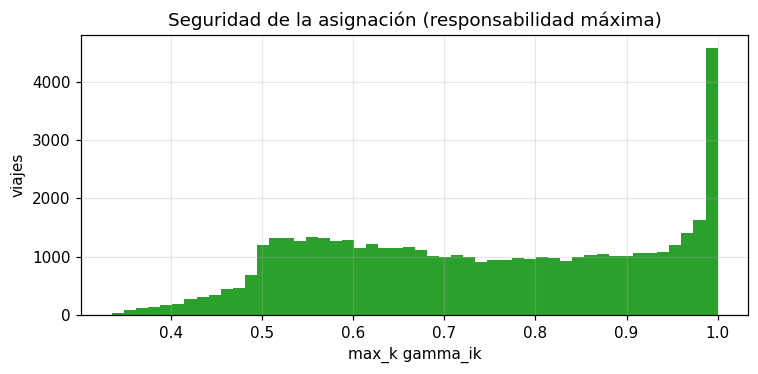

In [9]:
gmax = R.max(1); Hg = -(R * np.log2(np.clip(R, 1e-300, 1))).sum(1)
df["perfil"] = R.argmax(1); df["gamma_max"] = gmax; df["H_gamma"] = Hg
print(f"Viajes con gamma_max > 0.9: {100 * (gmax > .9).mean():.1f} %  |  gamma_max < 0.6 (ambiguos): {100 * (gmax < .6).mean():.1f} %")
print(f"Entropía media de las responsabilidades: {Hg.mean():.3f} bits (máx 2)")
print("\nEntropía media de gamma por perfil asignado:\n", df.groupby("perfil").H_gamma.mean().round(3).to_string())
print("\nEjemplos de viajes con pertenencia repartida:")
amb = df.sort_values("H_gamma", ascending=False).head(4).index
for i in amb:
    print(f"  {df.dist_km[i]:.2f} km, {df.duracion_min[i]:.1f} min, {df.pickup_datetime[i]:%a %H:%M} -> gamma = {R[i].round(3)}")
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.hist(gmax, bins=50, color="C2"); ax.set_xlabel("max_k gamma_ik"); ax.set_ylabel("viajes")
ax.set_title("Seguridad de la asignación (responsabilidad máxima)"); plt.tight_layout(); plt.savefig("figuras/rol3_gamma.png", bbox_inches="tight"); plt.show()

**Interpretación.** Solo el **25.4 %** de los viajes tiene una pertenencia “segura” ($\gamma_{max} > 0.9$) y el **27.3 %** es ambiguo ($\gamma_{max} < 0.6$); la entropía media de las responsabilidades es **0.81 bits** (de 2 posibles). Los perfiles **se solapan**: una asignación dura (como K-means) ocultaría que, p. ej., un viaje de 3.6 km y 40 min un jueves a las 11:20 es 34 % corto urbano, 36 % commuter y 29 % largo diurno. El perfil nocturno P3 es el más nítido (entropía media 0.60 bits) y el commuter P1 el más difuso (1.00 bit), porque sus viajes se parecen en distancia a los demás y solo se distinguen por la hora.

**Implicación de negocio:** para decisiones de precio o despacho por perfil, UrbanMove debe usar las **probabilidades** (p. ej. tarifa esperada $= \sum_k\gamma_{ik}\,\text{tarifa}_k$) y no la etiqueta más probable.

## 7. Perfiles de movilidad: interpretación de negocio
Caracterizamos cada perfil con **promedios ponderados por responsabilidad** $\bar v_k = \sum_i\gamma_{ik}v_i / N_k$ de variables que **no** entraron al modelo (fin de semana, aeropuerto, franja, macro-zona del Rol 2). Así la interpretación usa la pertenencia suave y no solo la asignación dura.

In [10]:
def wmean(v, k): return float((R[:, k] * v).sum() / R[:, k].sum())
aerop = df.zona_pickup.str.contains("Aeropuerto") | df.zona_dropoff.str.contains("Aeropuerto")
filas = []
for k in range(K):
    filas.append({"perfil": f"P{k}", "pi_k": pi_f[k], "viajes esperados (N_k)": R[:, k].sum(),
                  "dist media km": wmean(df.dist_km.values, k), "dur media min": wmean(df.duracion_min.values, k),
                  "vel media km/h": wmean(df.vel_kmh.values, k), "% fin de semana": 100 * wmean(df.fin_de_semana.values, k),
                  "% aeropuerto (orig o dest)": 100 * wmean(aerop.values.astype(float), k),
                  "% madrugada 0-5h": 100 * wmean((df.franja == "Madrugada (0-5h)").values.astype(float), k),
                  "% pico AM 6-9h": 100 * wmean((df.franja == "Pico AM (6-9h)").values.astype(float), k),
                  "% pico PM 16-19h": 100 * wmean((df.franja == "Pico PM (16-19h)").values.astype(float), k),
                  "% noche 20-23h": 100 * wmean((df.franja == "Noche (20-23h)").values.astype(float), k),
                  "% en macro-zona aeropuertos (Rol 2 C2/C3)": 100 * wmean(df.km.isin([2, 3]).values.astype(float), k)})
perfiles = pd.DataFrame(filas).set_index("perfil")
print(perfiles.round(2).T.to_string())

perfil                                           P0       P1       P2        P3
pi_k                                           0.36     0.12     0.18      0.34
viajes esperados (N_k)                     17972.34  5837.16  8864.92  16578.57
dist media km                                  1.59     3.45     4.90      4.72
dur media min                                  9.02    13.68    19.90     16.02
vel media km/h                                12.64    15.27    13.67     16.78
% fin de semana                               29.81    15.08    27.67     31.96
% aeropuerto (orig o dest)                     0.17     6.07    13.78      7.67
% madrugada 0-5h                               6.92     7.38     0.49     25.40
% pico AM 6-9h                                 6.95    83.72    15.36      0.01
% pico PM 16-19h                              30.92     0.00    10.89     26.34
% noche 20-23h                                18.66     0.00     0.22     44.80
% en macro-zona aeropuertos (Rol 2 C2/C3

**Perfiles de movilidad para UrbanMove (promedios ponderados por responsabilidad).**

| Perfil | Peso | Lectura de negocio |
|---|---|---|
| **P0 Corto urbano** | 36 % | 1.6 km / 9 min en promedio, casi sin aeropuerto (0.2 %). Alta rotación: el conductor queda libre rápido y cerca. |
| **P1 Commuter AM** | 12 % | **83.7 % ocurre entre 6 y 9 a. m.** y solo **15 %** en fin de semana. Demanda muy predecible en hora → posicionamiento programado. |
| **P2 Largo diurno** | 18 % | 4.9 km / 19.9 min, **13.8 % con aeropuerto** (la mayor proporción). Ocupa al conductor más tiempo en horas de tráfico: candidato a tarifa dinámica por congestión. |
| **P3 Nocturno** | 34 % | **70 %** entre 20 h y 5 h, **32 %** en fin de semana, el más rápido (16.8 km/h). Es el perfil de ocio nocturno que el Rol 1 vio concentrado en East/West Village. |

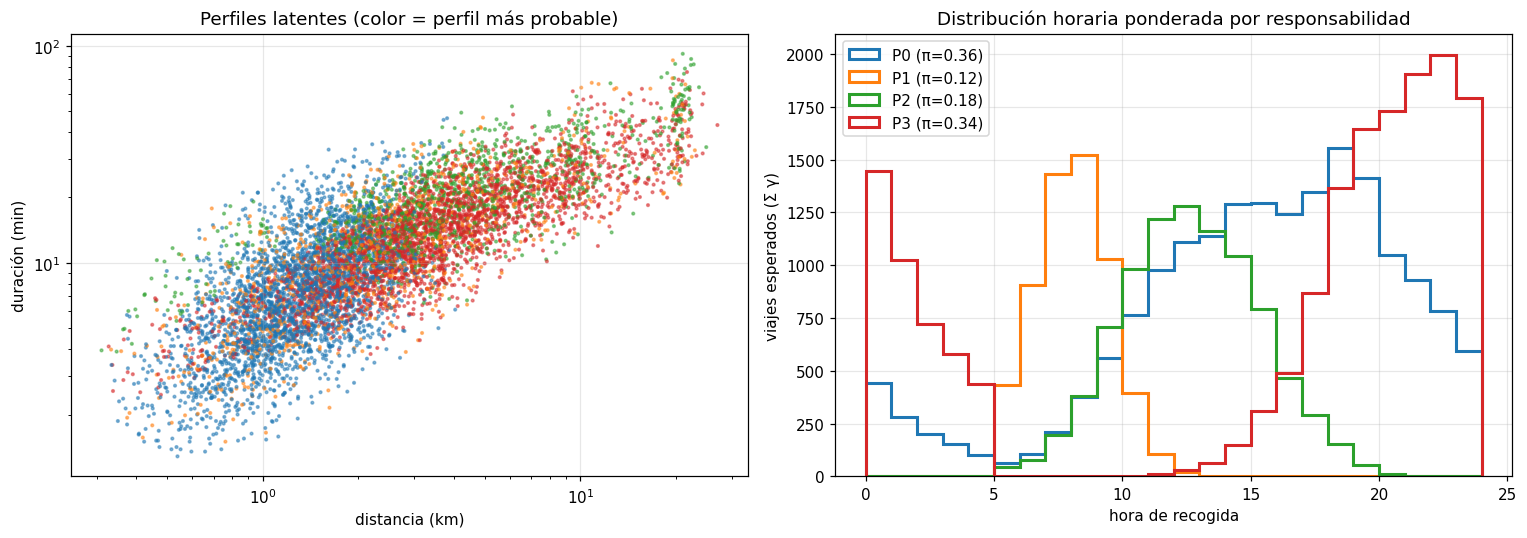

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
pal = sns.color_palette("tab10", K)
idx = np.random.default_rng(1).choice(N, 8000, replace=False)
axs[0].scatter(df.dist_km[idx], df.duracion_min[idx], c=[pal[p] for p in df.perfil[idx]], s=3, alpha=.5)
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("distancia (km)"); axs[0].set_ylabel("duración (min)")
axs[0].set_title("Perfiles latentes (color = perfil más probable)")
for k in range(K):
    axs[1].hist((df.hora_desp + HORA_CORTE) % 24, bins=24, range=(0, 24), weights=R[:, k], histtype="step", lw=2, color=pal[k], label=f"P{k} (π={pi_f[k]:.2f})")
axs[1].set_xlabel("hora de recogida"); axs[1].set_ylabel("viajes esperados (Σ γ)"); axs[1].set_title("Distribución horaria ponderada por responsabilidad"); axs[1].legend()
plt.tight_layout(); plt.savefig("figuras/rol3_perfiles.png", bbox_inches="tight"); plt.show()

In [12]:
res = {
    "K": K, "variables": NOMBRES, "hora_corte": HORA_CORTE, "N": int(N), "tol": 1e-6,
    "bic": bic.BIC.round(1).to_dict(),
    "pi": pi_f.round(4).tolist(), "mu_estandarizado": mu_f.round(4).tolist(), "mu_original": mu_orig.round(4).tolist(),
    "Sigma_original": S_orig.round(4).tolist(),
    "parametros_legibles": params.round(3).reset_index().to_dict("records"),
    "mejor_corrida": {"init": best["init"], "seed": int(best["seed"]), "iteraciones": int(best["n_iter"]), "loglik_viaje": best["ll"]},
    "sklearn_loglik_viaje": float(sk.score(X)), "sklearn_iter": int(sk.n_iter_),
    "inicializaciones": resumen_init.round(5).reset_index().to_dict("records"),
    "pct_gamma_mayor_09": float(100 * (gmax > .9).mean()), "pct_gamma_menor_06": float(100 * (gmax < .6).mean()),
    "H_gamma_media": float(Hg.mean()),
    "perfiles": perfiles.round(3).reset_index().to_dict("records"),
}
utils.guardar_resultados("rol3.json", res)
print("Guardado resultados/rol3.json")

Guardado resultados/rol3.json
